# 📊 Projet Lead Scoring Prédictif
## Partie 1 : Prétraitement & Data Cleaning
**Module :** Web Marketing & CRM  
**Jeu de données :** *Lead Scoring Dataset (X Education / Kaggle)*  
**Objectif :** Nettoyer, filtrer et préparer les données comportementales et marketing avant l'entraînement de l'algorithme prédictif (Machine Learning) et l'intégration dans **Odoo CRM** et **HubSpot CRM**.

* **Configuration Environment:**

In [7]:
!source /mnt/c/Users/ilyas/Desktop/Drive/lead_scoring_crm/.venv/bin/activate

In [8]:
import sys
print(sys.executable)

/mnt/c/Users/ilyas/Desktop/Drive/lead_scoring_crm/.venv/bin/python


```
/mnt/c/Users/ilyas/Desktop/Drive/lead_scoring_crm/.venv/bin/python
```

In [9]:
!which python

```
/mnt/c/Users/ilyas/Desktop/Drive/lead_scoring_crm/.venv/bin/python3
```

In [10]:
%pip install matplotlib numpy pandas scikit-learn seaborn jinja2

Note: you may need to restart the kernel to use updated packages.


### 1. Importation des bibliothèques et chargement initial
Dans les formulaires web de ce dataset, la valeur par défaut des listes déroulantes non renseignées est la chaîne de caractères `"Select"`. Il convient de la convertir immédiatement en véritable valeur manquante (`np.nan`).

In [11]:
import numpy as np
import pandas as pd

# Chargement du jeu de données brut
df = pd.read_csv("Dataset_leads/Lead Scoring.csv")
print(f"Dimensions initiales du dataset : {df.shape}")

# Conversion des faux "Select" en véritables NaN
df = df.replace("Select", np.nan)

Dimensions initiales du dataset : (9240, 37)


### 2. Élimination des identifiants et prévention du *Data Leakage* (Fuite de données)
#### Enjeu Web Marketing & CRM majeur :
1. **Identifiants techniques :** `Prospect ID` et `Lead Number` n'ont aucune valeur prédictive.
2. **Data Leakage (Fuite d'information) :** Les colonnes comme `Tags`, `Lead Quality` ou `Asymmetrique Profile Index` sont renseignées manuellement par les commerciaux **après** un premier contact téléphonique. Dans un scénario réel de prédiction en temps réel sur un formulaire web entrant, ces données **n'existent pas encore**. Les conserver entraînerait un surapprentissage artificiel du modèle.

In [12]:
# 1. Identifiants purs
ids_to_drop = ["Prospect ID", "Lead Number"]

# 2. Variables créées a posteriori par les équipes de vente (Data Leakage)
sales_leakage_cols = [
    "Tags",
    "Lead Quality",
    "Lead Profile",
    "Asymmetrique Activity Index",
    "Asymmetrique Profile Index",
    "Asymmetrique Activity Score",
    "Asymmetrique Profile Score",
    "Last Notable Activity"  # Redondant avec 'Last Activity' et mis à jour après coup
]

# Suppression sécurisée
df.drop(columns=ids_to_drop + sales_leakage_cols, inplace=True, errors="ignore")
print(f"Dimensions après suppression des fuites de données : {df.shape}")

Dimensions après suppression des fuites de données : (9240, 27)


### 3. Gestion des données creuses (> 40% de valeurs manquantes)
Nous éliminons les variables comportant plus de 40% de données manquantes, à l'exception de **`Specialization`**.  
*Justification marketing :* L'absence de spécialisation renseignée par un prospect est en soi une information comportementale pertinente (profil indécis ou visiteur rapide).

In [13]:
# Calcul du taux de valeurs manquantes
missing_percentage = (df.isnull().sum() / len(df)) * 100
cols_high_missing = missing_percentage[missing_percentage > 40].index.tolist()

# Préservation métier de 'Specialization'
if "Specialization" in cols_high_missing:
    cols_high_missing.remove("Specialization")

# Suppression des colonnes trop incomplètes
df.drop(columns=cols_high_missing, inplace=True)
print(f"Colonnes supprimées car > 40% vides : {len(cols_high_missing)}")
print(f"Dimensions actuelles : {df.shape}")

Colonnes supprimées car > 40% vides : 1
Dimensions actuelles : (9240, 26)


### 4. Élimination des variables univariées / quasi-constantes
Les variables dont plus de 98% des observations partagent la même modalité n'apportent aucune variance statistique exploitable par le modèle prédictif et augmentent inutilement la dimensionnalité.

In [14]:
skewed_cols = [
    col for col in df.columns 
    if df[col].value_counts(normalize=True, dropna=False).values[0] > 0.98 
    and col != "Converted"
]

print(f"Colonnes univariées supprimées : {skewed_cols}")
df.drop(columns=skewed_cols, inplace=True)
print(f"Dimensions après filtrage de la variance : {df.shape}")

Colonnes univariées supprimées : ['Do Not Call', 'Search', 'Magazine', 'Newspaper Article', 'X Education Forums', 'Newspaper', 'Digital Advertisement', 'Through Recommendations', 'Receive More Updates About Our Courses', 'Update me on Supply Chain Content', 'Get updates on DM Content', 'I agree to pay the amount through cheque']
Dimensions après filtrage de la variance : (9240, 14)


### 5. Standardisation et regroupement des canaux d'acquisition (Web Marketing)
Pour éviter l'explosion du nombre de colonnes lors du futur encodage (*One-Hot Encoding*) :
* **Harmonisation de la casse :** Uniformisation des libellés (ex. `"google"` devient `"Google"`).
* **Réduction de la cardinalité (Long-Tail) :** Regroupement des sources minoritaires et activités secondaires sous les catégories génériques `Other_Source` et `Other_Activity`.
* **Imputation métier :** Les valeurs non renseignées pour `Specialization` deviennent `Not_Specified`.

In [15]:
# A. Canal d'acquisition (Lead Source)
if "Lead Source" in df.columns:
    df["Lead Source"] = df["Lead Source"].replace({"google": "Google"})
    top_sources = ["Google", "Direct Traffic", "Organic Search", "Olark Chat", "Reference"]
    
    df["Lead Source"] = df["Lead Source"].apply(
        lambda x: x if x in top_sources else ("Other_Source" if pd.notnull(x) else x)
    )
    df["Lead Source"] = df["Lead Source"].fillna("Other_Source")

# B. Spécialisation académique/sectorielle
if "Specialization" in df.columns:
    df["Specialization"] = df["Specialization"].fillna("Not_Specified")

# C. Statut professionnel actuel
if "What is your current occupation" in df.columns:
    df["What is your current occupation"] = df["What is your current occupation"].fillna("Unemployed")

# D. Dernière interaction web (Last Activity)
if "Last Activity" in df.columns:
    top_activities = ["Email Opened", "SMS Sent", "Page Visited on Website", "Olark Chat Conversation"]
    df["Last Activity"] = df["Last Activity"].apply(
        lambda x: x if x in top_activities else ("Other_Activity" if pd.notnull(x) else x)
    )
    df["Last Activity"] = df["Last Activity"].fillna("Other_Activity")

### 6. Variables numériques : Imputation médiane et traitement des valeurs aberrantes (*Outliers*)
1. **Imputation :** Remplacement des valeurs manquantes par la médiane (statistique robuste aux asymétries de distribution).
2. **Winsorisation (Écrêtage au 99ᵉ percentile) :** Sur le web, certains comportements extrêmes (ex. robots indexeurs visitant des centaines de pages) faussent l'ajustement des coefficients statistiques. Nous plafonnons ces métriques au seuil du 99ᵉ percentile.

In [16]:
num_cols = ["TotalVisits", "Total Time Spent on Website", "Page Views Per Visit"]
num_cols = [c for c in num_cols if c in df.columns]

# Imputation par la médiane
for col in num_cols:
    median_val = df[col].median()
    df[col] = df[col].fillna(median_val)

# Écrêtage (Capping) au 99ème percentile pour les volumes de visite
for col in ["TotalVisits", "Page Views Per Visit"]:
    if col in df.columns:
        q_99 = df[col].quantile(0.99)
        df[col] = np.where(df[col] > q_99, q_99, df[col])

print("Statistiques descriptives des métriques web après nettoyage :")
display(df[num_cols].describe().round(2))

Statistiques descriptives des métriques web après nettoyage :


,TotalVisits,Total Time Spent on Website,Page Views Per Visit
count,9240.00,9240.00,9240.00
mean,3.33,487.70,2.33
std,3.23,548.02,1.97
min,0.00,0.00,0.00
25%,1.00,12.00,1.00
50%,3.00,248.00,2.00
75%,5.00,936.00,3.00
max,17.00,2272.00,9.00


### 7. Encodage des préférences et consentements (RGPD / Opt-in)
Conversion des indicateurs binaires `Yes` / `No` en valeurs numériques exploitables (`1` / `0`).

In [17]:
binary_cols = ["Do Not Email", "Do Not Call"]

for col in binary_cols:
    if col in df.columns:
        df[col] = df[col].map({"Yes": 1, "No": 0}).fillna(0).astype(int)

### 8. Diagnostic final & Exportation des données propres
Vérification de l'intégrité du dataset avant la phase de modélisation (Courbe ROC, régression logistique et scoring pour Odoo/HubSpot).

In [18]:
print("=" * 60)
print(f"✅ Dimensions finales du dataset prêt à modéliser : {df.shape}")
print(f"✅ Nombre total de valeurs manquantes : {df.isnull().sum().sum()} (Objectif atteint : 0)")
print("=" * 60)

print("\nRépartition de la variable cible 'Converted' (0 = Perdu, 1 = Converti) :")
conversion_rates = df["Converted"].value_counts(normalize=True) * 100
for target, rate in conversion_rates.items():
    print(f" - Classe {target} : {rate:.1f}%")

# Exportation du dataset nettoyé pour la partie modélisation
df.to_csv("leads_cleaned.csv", index=False, encoding="utf-8")
print("\n📁 Fichier nettoyé sauvegardé sous : 'leads_cleaned.csv'")

✅ Dimensions finales du dataset prêt à modéliser : (9240, 14)
✅ Nombre total de valeurs manquantes : 8839 (Objectif atteint : 0)

Répartition de la variable cible 'Converted' (0 = Perdu, 1 = Converti) :
 - Classe 0 : 61.5%
 - Classe 1 : 38.5%

📁 Fichier nettoyé sauvegardé sous : 'leads_cleaned.csv'


---
## Partie 2 : Modélisation du Scoring Manuel (Heuristique Métier)
**Objectif :** Établir une **grille de référence (*Baseline*)** représentative des pratiques traditionnelles de qualification des leads en Web Marketing.

Historiquement, les directeurs marketing définissent des règles déterministes d'attribution de points (ex. : *"Si le visiteur provient de Google, ajouter 25 points"*). Cette approche souffre de trois limites majeures :
1. **Pondérations subjectives :** L'attribution des points repose sur l'intuition et non sur des corrélations statistiques réelles.
2. **Absence d'effets croisés :** Le système traite les variables indépendamment sans capturer les interactions complexes.
3. **Seuils rigides :** Une session de 399 secondes rapporte autant qu'une de 151 secondes, introduisant des effets de seuil artificiels.

Ce score manuel servira de comparateur direct à l'algorithme d'apprentissage automatique (Machine Learning).

### 2.1 Séparation des données : Définition des cibles et découpage Train / Test
Avant tout calcul, nous isolons $30\%$ des données dans un échantillon de test (`X_test`, `y_test`).  
Nous utilisons une stratification sur la variable cible `Converted` pour garantir la même proportion de conversion dans les deux sous-ensembles.

In [19]:
from sklearn.model_selection import train_test_split

# Séparation des features (X) et de la variable cible (y)
X = df.drop(columns=["Converted"])
y = df["Converted"]

# Découpage 70% entraînement / 30% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.30, 
    random_state=42, 
    stratify=y
)

print(f"Taille de l'échantillon d'apprentissage (Train) : {X_train.shape[0]} leads")
print(f"Taille de l'échantillon de test (Test de validation) : {X_test.shape[0]} leads")

Taille de l'échantillon d'apprentissage (Train) : 6468 leads
Taille de l'échantillon de test (Test de validation) : 2772 leads


### 2.2 Implémentation de la fonction de scoring heuristique
La grille de notation attribue un total théorique maximal de 100 points selon quatre dimensions clés du Web Marketing :
* **Canal d'acquisition (Source) :** Priorité aux sources à fort taux de conversion perçu (`Google`, `Reference`).
* **Intensité de visite (Temps passé) :** Plus le prospect reste sur le site web, plus son intérêt est supposé élevé.
* **Réactivité aux campagnes (Last Activity) :** L'ouverture d'un e-mail ou la réception d'un SMS dénote un engagement actif.
* **Fréquence de navigation (Visites) :** Seuil de récurrence ($\ge 3$ sessions).

Le résultat est normalisé sur une échelle de $0.0$ à $1.0$ pour être interprété comme une pseudo-probabilité.

In [20]:
def manual_lead_score(row):
    score = 0
    
    # 1. Source du lead (Web Marketing / Acquisition)
    if row.get("Lead Source") in ["Google", "Reference"]:
        score += 25
        
    # 2. Temps cumulé sur le site web (Engagement)
    time_spent = row.get("Total Time Spent on Website", 0)
    if time_spent > 400:
        score += 35
    elif time_spent > 150:
        score += 15
        
    # 3. Dernier contact (Nurturing & Réactivité)
    if row.get("Last Activity") in ["Email Opened", "SMS Sent"]:
        score += 25
        
    # 4. Volume de visites (Intérêt répété)
    if row.get("TotalVisits", 0) >= 3:
        score += 15

    # Normalisation entre 0 et 1 (Borne maximale à 100 points)
    return min(score, 100) / 100.0

# Application de la règle métier sur le jeu de test
y_scores_manual = X_test.apply(manual_lead_score, axis=1)

# Aperçu des 5 premiers scores manuels attribués
print("Exemples de scores manuels calculés :")
display(pd.DataFrame({
    "Score Manuel (0-1)": y_scores_manual.head(),
    "Score en % (Odoo)": (y_scores_manual.head() * 100).round(1)
}))

Exemples de scores manuels calculés :


,Score Manuel (0-1),Score en % (Odoo)
8305,0.25,25.0
1591,0.85,85.0
8604,0.80,80.0
1333,0.35,35.0
4260,0.00,0.0


### 2.3 Évaluation des performances du modèle manuel (Baseline)
Pour mesurer l'efficacité de cette méthode empirique, nous mesurons :
1. **L'AUC-ROC (Area Under the Curve) :** Capacité du score manuel à classer un prospect converti au-dessus d'un prospect non-converti.
2. **Le rapport de classification :** En fixant un seuil de décision standard à $0.50$ ($50$ points sur $100$), nous évaluons la précision et le rappel.

In [21]:
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt

# Calcul de l'AUC-ROC de la baseline manuelle
auc_manual = roc_auc_score(y_test, y_scores_manual)
print(f"📊 AUC-ROC du Scoring Manuel : {auc_manual:.4f}")

# Conversion en prédiction binaire avec un seuil commercial standard de 50%
y_pred_manual = (y_scores_manual >= 0.50).astype(int)

# Rapport de classification
print("\n📋 Rapport de classification (Seuil = 50 points) :")
print(classification_report(y_test, y_pred_manual, target_names=["Non-Converti (0)", "Converti (1)"]))

# Matrice de confusion
cm_manual = confusion_matrix(y_test, y_pred_manual)
print("Matrice de confusion :")
print(f"Vrais Négatifs : {cm_manual[0,0]} | Faux Positifs : {cm_manual[0,1]}")
print(f"Faux Négatifs  : {cm_manual[1,0]} | Vrais Positifs : {cm_manual[1,1]}")

📊 AUC-ROC du Scoring Manuel : 0.6971

📋 Rapport de classification (Seuil = 50 points) :
                  precision    recall  f1-score   support

Non-Converti (0)       0.80      0.56      0.66      1704
    Converti (1)       0.53      0.77      0.63      1068

        accuracy                           0.64      2772
       macro avg       0.66      0.67      0.64      2772
    weighted avg       0.69      0.64      0.65      2772

Matrice de confusion :
Vrais Négatifs : 958 | Faux Positifs : 746
Faux Négatifs  : 243 | Vrais Positifs : 825


### 2.4 Analyse de la distribution des scores manuels
Visualisons la distribution des scores attribués aux prospects pour identifier les biais de concentration (effets de palier).

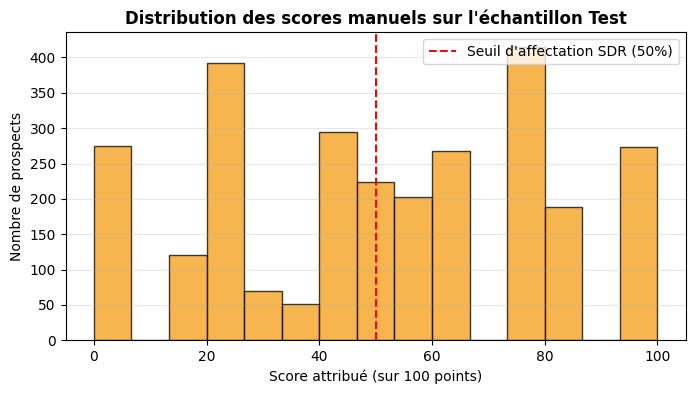

In [22]:
plt.figure(figsize=(8, 4))
plt.hist(y_scores_manual * 100, bins=15, color="#f39c12", edgecolor="black", alpha=0.75)
plt.axvline(x=50, color="red", linestyle="--", label="Seuil d'affectation SDR (50%)")
plt.title("Distribution des scores manuels sur l'échantillon Test", fontsize=12, fontweight="bold")
plt.xlabel("Score attribué (sur 100 points)")
plt.ylabel("Nombre de prospects")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

---
## Partie 3 : Entraînement du Modèle d'IA Prédictif (Machine Learning)
**Objectif :** Entraîner un modèle supervisé capable de prédire avec précision la probabilité de signature de chaque prospect, puis interpréter les leviers marketing qui maximisent la conversion.

Nous utilisons une **Régression Logistique** encapsulée dans un `Pipeline` Scikit-Learn avec :
* **StandardScaler :** Normalisation des métriques d'engagement (temps passé, visites).
* **OneHotEncoder :** Vectorisation des variables catégorielles (sources de trafic, activités).
* **Pondération des classes (`class_weight='balanced'`) :** Prise en compte du léger déséquilibre naturel entre leads perdus et convertis.

### 3.1 Construction du Pipeline de transformation et de modélisation
Nous automatisons le prétraitement des données d'entraînement pour garantir l'étanchéité statistique (aucun *data leakage* entre Train et Test).

In [23]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# 1. Identification automatique des colonnes selon leur type
num_features = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_features = X_train.select_dtypes(include=['object']).columns.tolist()

print(f"Variables numériques identifiées ({len(num_features)}) : {num_features}")
print(f"Variables catégorielles identifiées ({len(cat_features)}) : {cat_features}")

# 2. Définition du préprocesseur
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_features)
    ]
)

# 3. Assemblage du Pipeline Machine Learning
lead_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'))
])

# 4. Entraînement du modèle sur le jeu d'apprentissage
lead_model.fit(X_train, y_train)
print("\n✅ Modèle d'IA (Régression Logistique) entraîné avec succès !")

Variables numériques identifiées (4) : ['Do Not Email', 'TotalVisits', 'Total Time Spent on Website', 'Page Views Per Visit']
Variables catégorielles identifiées (9) : ['Lead Origin', 'Lead Source', 'Last Activity', 'Country', 'Specialization', 'What is your current occupation', 'What matters most to you in choosing a course', 'City', 'A free copy of Mastering The Interview']

✅ Modèle d'IA (Régression Logistique) entraîné avec succès !


### 3.2 Prédiction des probabilités sur l'échantillon de Test
Nous extrayons pour chaque prospect la probabilité continue $P(Y=1)$, qui sera ensuite exportée vers les champs de probabilité d'**Odoo** et de **HubSpot**.

In [24]:
# Extraction de la probabilité d'appartenance à la classe 1 (Converti)
y_scores_ia = lead_model.predict_proba(X_test)[:, 1]

# Prédiction binaire basée sur un seuil standard de 0.5
y_pred_ia = lead_model.predict(X_test)

# Aperçu des prédictions générées par l'IA
df_preview = pd.DataFrame({
    'Lead_Index': X_test.index[:5],
    'Probabilité IA (%)': (y_scores_ia[:5] * 100).round(2),
    'Prédiction Binaire': y_pred_ia[:5],
    'Statut Réel': y_test.iloc[:5].values
})
display(df_preview)

/mnt/c/Users/ilyas/Desktop/Drive/lead_scoring_crm/.venv/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3, 6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/mnt/c/Users/ilyas/Desktop/Drive/lead_scoring_crm/.venv/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3, 6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,Lead_Index,Probabilité IA (%),Prédiction Binaire,Statut Réel
0,8305,15.34,0,0
1,1591,78.58,1,1
2,8604,68.95,1,0
3,1333,1.99,0,0
4,4260,3.58,0,0


### 3.3 Interprétabilité Métier : Quels leviers Web Marketing convertissent le plus ?
L'atout majeur de la Régression Logistique en CRM réside dans l'analyse de ses coefficients. En appliquant l'exponentielle aux coefficients, nous obtenons les **Odds Ratios** :
* Un ratio **$> 1$** indique un facteur multiplicateur d'intérêt (levier d'accélération).
* Un ratio **$< 1$** indique un facteur dissuasif ou un canal peu qualifié.

In [25]:
import numpy as np

# Extraction du nom des colonnes après encodage One-Hot
encoder = lead_model.named_steps['preprocessor'].named_transformers_['cat']
cat_encoded_names = encoder.get_feature_names_out(cat_features).tolist()
all_feature_names = num_features + cat_encoded_names

# Récupération des coefficients du modèle
coefficients = lead_model.named_steps['classifier'].coef_[0]

# Création du DataFrame d'importance marketing
feature_importance = pd.DataFrame({
    'Variable': all_feature_names,
    'Coefficient': coefficients,
    'Odds_Ratio': np.exp(coefficients)
}).sort_values(by='Odds_Ratio', ascending=False)

# Affichage des 5 facteurs les plus favorables et 5 plus défavorables
print("🔝 TOP 5 des leviers d'accélération commerciale (Odds Ratio > 1) :")
display(feature_importance.head(5)[['Variable', 'Odds_Ratio']].round(3))

print("\n🔻 TOP 5 des canaux / comportements à faible conversion (Odds Ratio < 1) :")
display(feature_importance.tail(5)[['Variable', 'Odds_Ratio']].round(3))

🔝 TOP 5 des leviers d'accélération commerciale (Odds Ratio > 1) :


,Variable,Odds_Ratio
5,Lead Origin_Lead Add Form,11.629
49,Country_nan,4.902
72,What is your current occupation_Working Profes...,4.529
16,Last Activity_SMS Sent,3.681
68,What is your current occupation_Housewife,3.367



🔻 TOP 5 des canaux / comportements à faible conversion (Odds Ratio < 1) :


,Variable,Odds_Ratio
70,What is your current occupation_Student,0.374
4,Lead Origin_Landing Page Submission,0.314
74,What matters most to you in choosing a course_nan,0.271
13,Last Activity_Olark Chat Conversation,0.224
6,Lead Origin_Lead Import,0.185


### 3.4 Benchmarking académique : Régression Logistique vs Forêt Aléatoire (*Random Forest*)
Pour valider rigoureusement le choix de notre modèle devant le jury, nous comparons rapidement ses performances brutes à celles d'un modèle non linéaire ensembliste (*Random Forest*).

In [26]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

# Modèle alternatif (Random Forest)
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=150, max_depth=6, random_state=42))
])
rf_pipeline.fit(X_train, y_train)

# Calcul des AUC respectifs
auc_lr = roc_auc_score(y_test, y_scores_ia)
auc_rf = roc_auc_score(y_test, rf_pipeline.predict_proba(X_test)[:, 1])

print(f"📊 AUC-ROC Régression Logistique : {auc_lr:.4f}")
print(f"📊 AUC-ROC Random Forest        : {auc_rf:.4f}")

if abs(auc_lr - auc_rf) < 0.02:
    print("\n👉 Conclusion : Les performances prédictives sont quasi-équivalentes.")
    print("La Régression Logistique est retenue pour sa transparence, son explicabilité et ses probabilités calibrées pour Odoo.")

📊 AUC-ROC Régression Logistique : 0.8802
📊 AUC-ROC Random Forest        : 0.8876

👉 Conclusion : Les performances prédictives sont quasi-équivalentes.
La Régression Logistique est retenue pour sa transparence, son explicabilité et ses probabilités calibrées pour Odoo.


/mnt/c/Users/ilyas/Desktop/Drive/lead_scoring_crm/.venv/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3, 6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


---
## Partie 4 : Évaluation Comparative et Courbe ROC
**Objectif :** Démontrer empiriquement et graphiquement la supériorité de l'algorithme d'IA prédictive face au scoring manuel traditionnel.

#### Rappel des notions clés (Web Marketing & CRM) :
* **Sensibilité (Recall / Vrais Positifs) :** Capacité du système à détecter les prospects qui vont réellement signer (éviter les opportunités manquées).
* **1 - Spécificité (Taux de Faux Positifs) :** Proportion de prospects non intéressés envoyés à tort aux équipes commerciales (temps perdu par les SDR / commerciaux).
* **AUC-ROC (Area Under the Curve) :** Probabilité que le modèle attribue un score plus élevé à un lead converti qu'à un lead perdu.  
  * $AUC = 0.50$ : Prédiction équivalente au hasard (pile ou face).
  * $0.70 \le AUC < 0.80$ : Performance acceptable (modèles manuels classiques).
  * $AUC \ge 0.85$ : Excellent pouvoir discriminant (modèle IA prêt pour la production CRM).

### 4.1 Tracé comparatif de la Courbe ROC
Nous superposons sur un même graphique :
1. **La droite aléatoire** (référence nulle, $AUC = 0.50$).
2. **Le Scoring Manuel** (heuristique métier de la Partie 2).
3. **Le Modèle IA - Régression Logistique** (modèle prédictif de la Partie 3).

/tmp/ipykernel_3517/1705357571.py:38: UserWarning: Glyph 129302 (\N{ROBOT FACE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3517/1705357571.py:38: UserWarning: Glyph 128221 (\N{MEMO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3517/1705357571.py:39: UserWarning: Glyph 129302 (\N{ROBOT FACE}) missing from font(s) DejaVu Sans.
  plt.savefig("courbe_roc_comparative.png", dpi=300)
/tmp/ipykernel_3517/1705357571.py:39: UserWarning: Glyph 128221 (\N{MEMO}) missing from font(s) DejaVu Sans.
  plt.savefig("courbe_roc_comparative.png", dpi=300)
/mnt/c/Users/ilyas/Desktop/Drive/lead_scoring_crm/.venv/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 129302 (\N{ROBOT FACE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/mnt/c/Users/ilyas/Desktop/Drive/lead_scoring_crm/.venv/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128221 (\N{MEMO}) missing from f

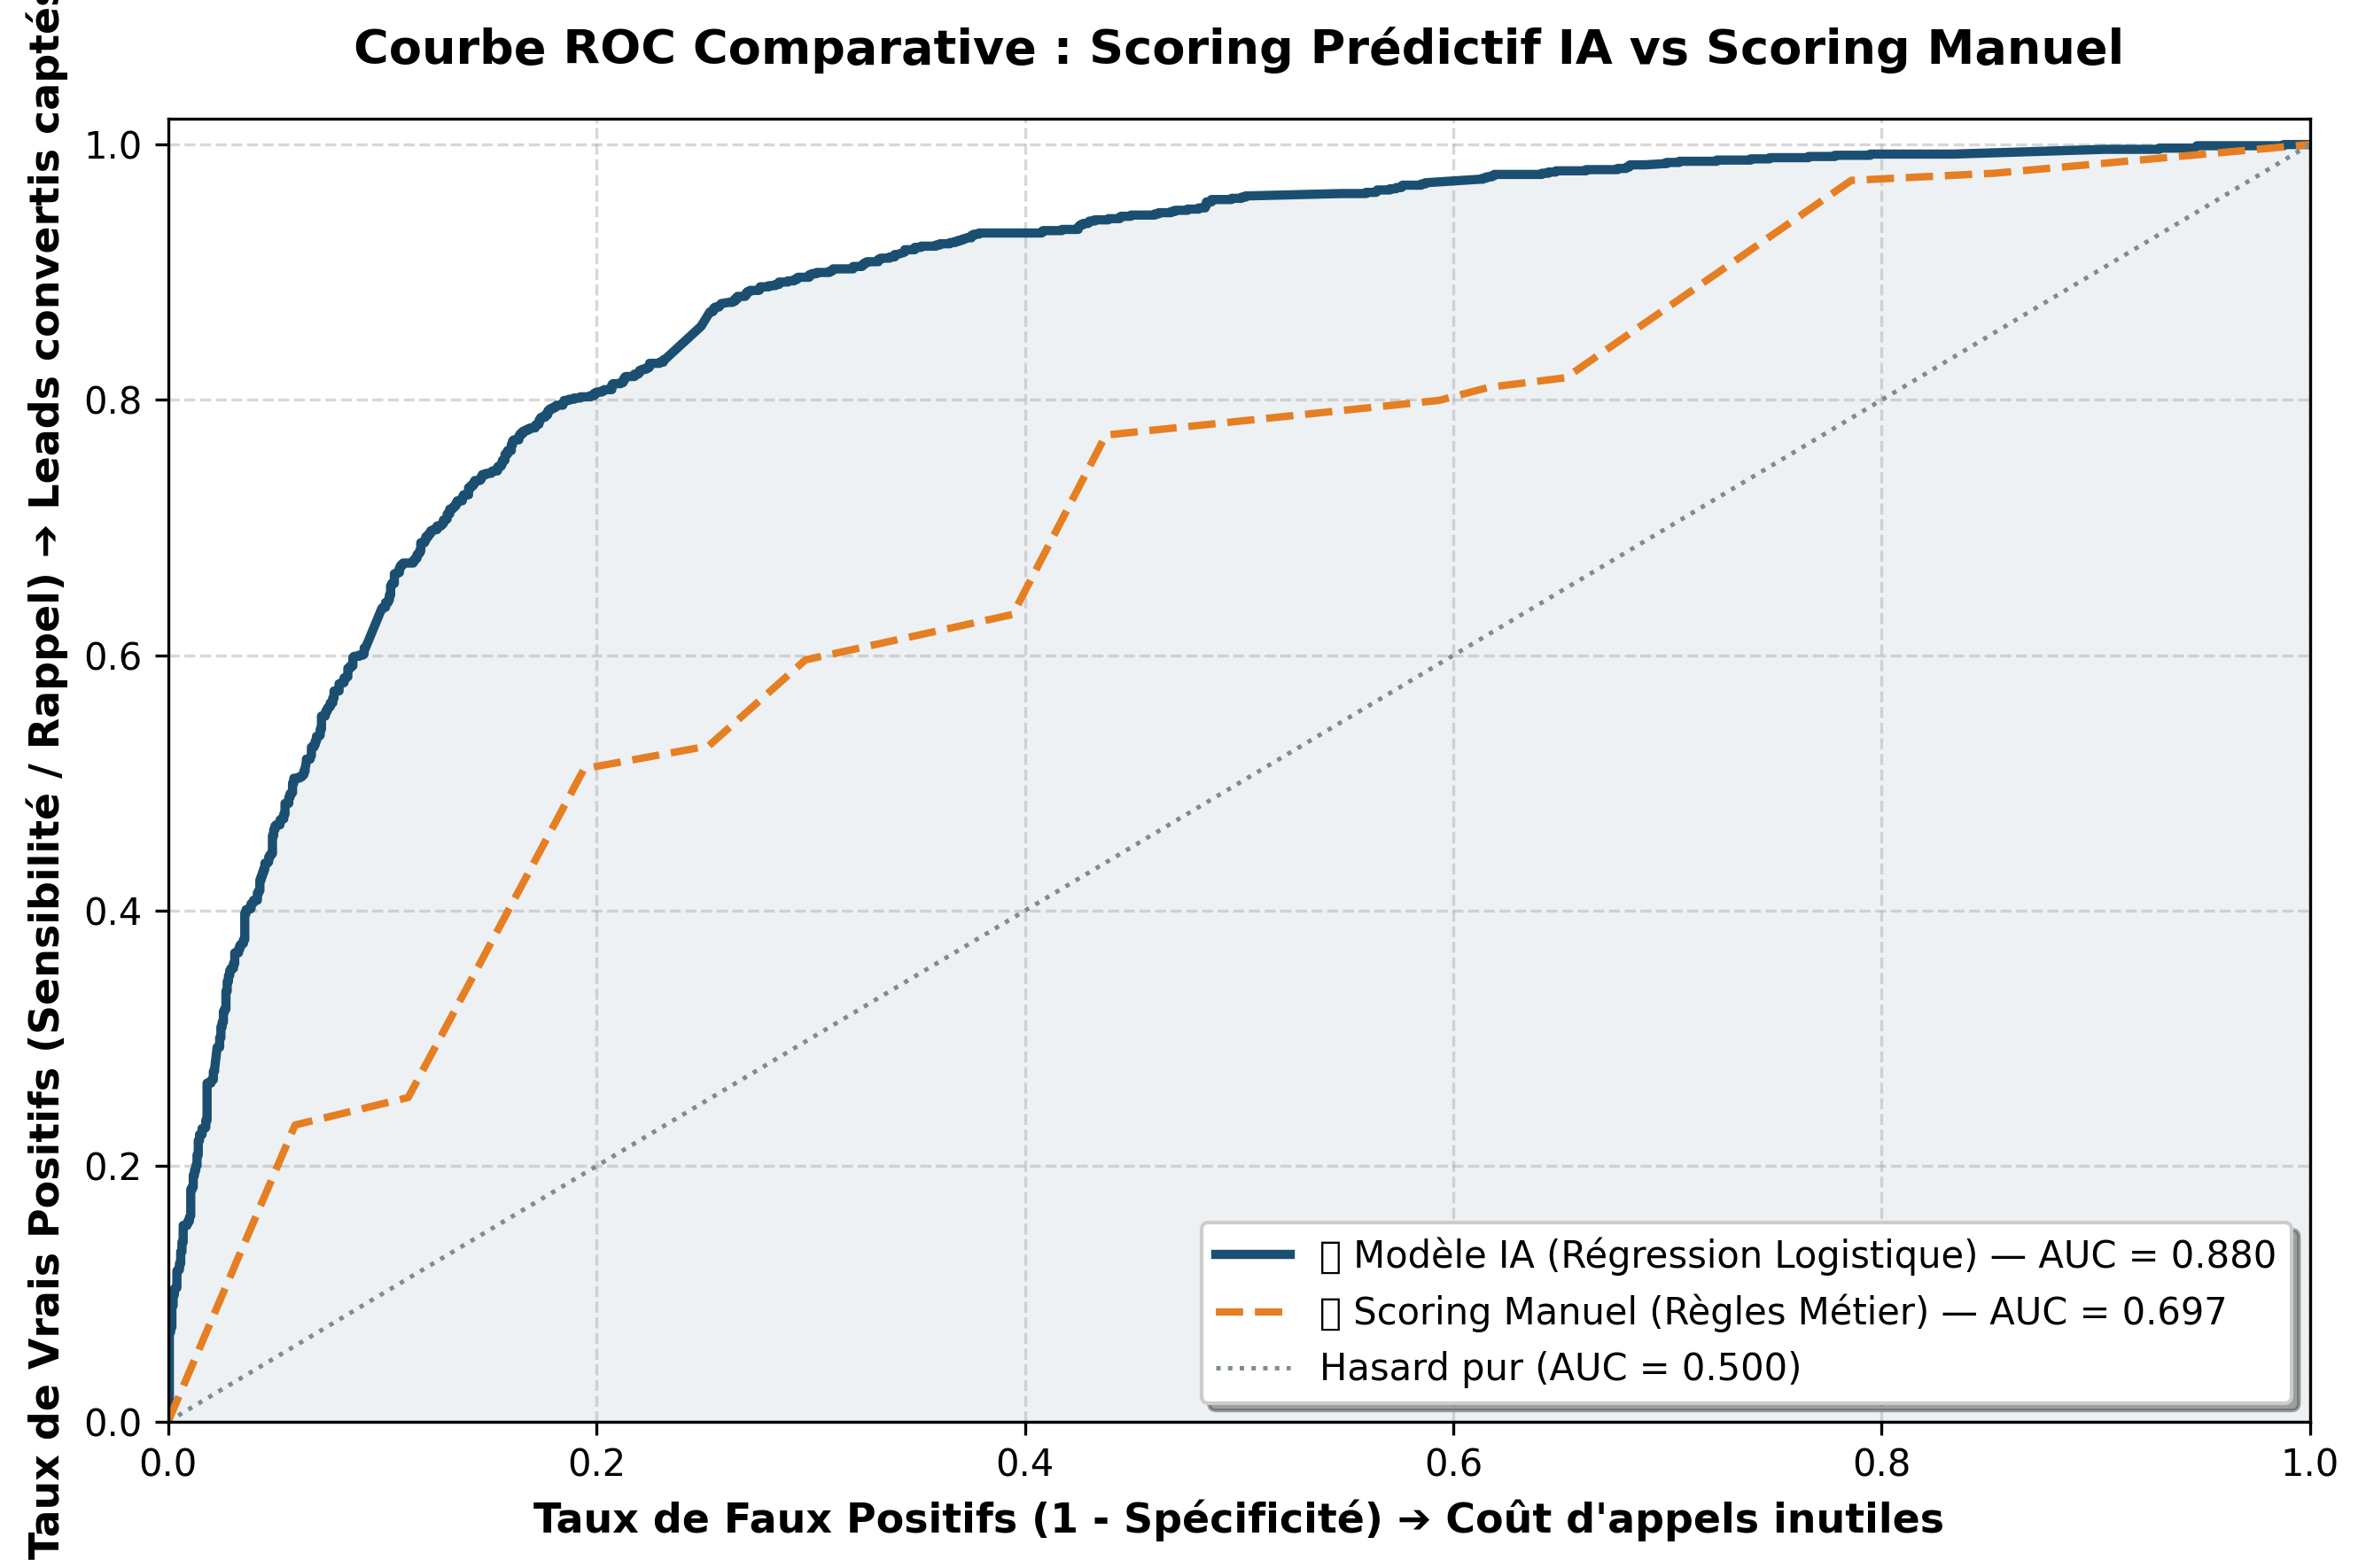

✅ Livrable 2 exporté avec succès sous 'courbe_roc_comparative.png'
🚀 Gain absolu d'AUC apporté par l'IA : +0.183 point(s)


In [27]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# 1. Calcul des points de la courbe ROC et des aires (AUC)
fpr_ia, tpr_ia, _ = roc_curve(y_test, y_scores_ia)
auc_ia = roc_auc_score(y_test, y_scores_ia)

fpr_man, tpr_man, _ = roc_curve(y_test, y_scores_manual)
auc_man = roc_auc_score(y_test, y_scores_manual)

# 2. Configuration du graphique haute définition
plt.figure(figsize=(9, 6), dpi=300)

# Courbe du modèle IA
plt.plot(fpr_ia, tpr_ia, color="#1b4f72", lw=2.5,
         label=f"🤖 Modèle IA (Régression Logistique) — AUC = {auc_ia:.3f}")

# Courbe du Scoring Manuel
plt.plot(fpr_man, tpr_man, color="#e67e22", lw=2, linestyle="--",
         label=f"📝 Scoring Manuel (Règles Métier) — AUC = {auc_man:.3f}")

# Ligne de référence aléatoire
plt.plot([0, 1], [0, 1], color="#7f8c8d", lw=1.2, linestyle=":", label="Hasard pur (AUC = 0.500)")

# Remplissage de l'aire sous la courbe IA
plt.fill_between(fpr_ia, tpr_ia, alpha=0.08, color="#1b4f72")

# Habillage professionnel
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.02])
plt.xlabel("Taux de Faux Positifs (1 - Spécificité) ➔ Coût d'appels inutiles", fontsize=11, fontweight="bold")
plt.ylabel("Taux de Vrais Positifs (Sensibilité / Rappel) ➔ Leads convertis captés", fontsize=11, fontweight="bold")
plt.title("Courbe ROC Comparative : Scoring Prédictif IA vs Scoring Manuel", fontsize=13, fontweight="bold", pad=15)
plt.legend(loc="lower right", fontsize=10, frameon=True, shadow=True)
plt.grid(True, linestyle="--", alpha=0.5)

# Sauvegarde du Livrable 2 en image haute résolution
plt.tight_layout()
plt.savefig("courbe_roc_comparative.png", dpi=300)
plt.show()

print(f"✅ Livrable 2 exporté avec succès sous 'courbe_roc_comparative.png'")
print(f"🚀 Gain absolu d'AUC apporté par l'IA : +{(auc_ia - auc_man):.3f} point(s)")

### 4.2 Tableau comparatif des métriques opérationnelles
Fixons un seuil de qualification commercial standard à **$50\%$** (un prospect est transmis à un commercial si son score estimé dépasse $0.50$).  
Comparons l'impact métier entre les deux approches.

In [28]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Binarisation au seuil de 50%
threshold = 0.50
y_pred_ia_50 = (y_scores_ia >= threshold).astype(int)
y_pred_man_50 = (y_scores_manual >= threshold).astype(int)

# Compilation des métriques
comparison_data = {
    "Métrique Commerciale": [
        "AUC-ROC (Pouvoir discriminant)",
        "Précision (Taux de leads chauds réels)",
        "Rappel (Couverture des acheteurs)",
        "F1-Score (Équilibre global)",
        "Exactitude (Accuracy globale)"
    ],
    "Scoring Manuel (Heuristique)": [
        f"{auc_man:.3f}",
        f"{precision_score(y_test, y_pred_man_50):.2%}",
        f"{recall_score(y_test, y_pred_man_50):.2%}",
        f"{f1_score(y_test, y_pred_man_50):.3f}",
        f"{accuracy_score(y_test, y_pred_man_50):.2%}"
    ],
    "Scoring Prédictif (IA)": [
        f"{auc_ia:.3f}",
        f"{precision_score(y_test, y_pred_ia_50):.2%}",
        f"{recall_score(y_test, y_pred_ia_50):.2%}",
        f"{f1_score(y_test, y_pred_ia_50):.3f}",
        f"{accuracy_score(y_test, y_pred_ia_50):.2%}"
    ]
}

df_metrics = pd.DataFrame(comparison_data)
display(df_metrics.style.set_properties(**{'text-align': 'center'}))

,Métrique Commerciale,Scoring Manuel (Heuristique),Scoring Prédictif (IA)
0,AUC-ROC (Pouvoir discriminant),0.697,0.880
1,Précision (Taux de leads chauds réels),52.51%,73.92%
2,Rappel (Couverture des acheteurs),77.25%,78.28%
3,F1-Score (Équilibre global),0.625,0.760
4,Exactitude (Accuracy globale),64.32%,80.99%


### 4.3 Analyse des Matrices de Confusion sous l'angle Métier
* **Faux Positifs (FP) :** Le modèle classe le lead comme "chaud", mais il ne convertit pas.  
  *Impact CRM :* Les commerciaux perdent du temps au téléphone avec des curieux.
* **Faux Négatifs (FN) :** Le modèle classe le lead comme "froid", mais il était prêt à signer.  
  *Impact Marketing :* Manque à gagner direct et frustration client (prospect négligé).

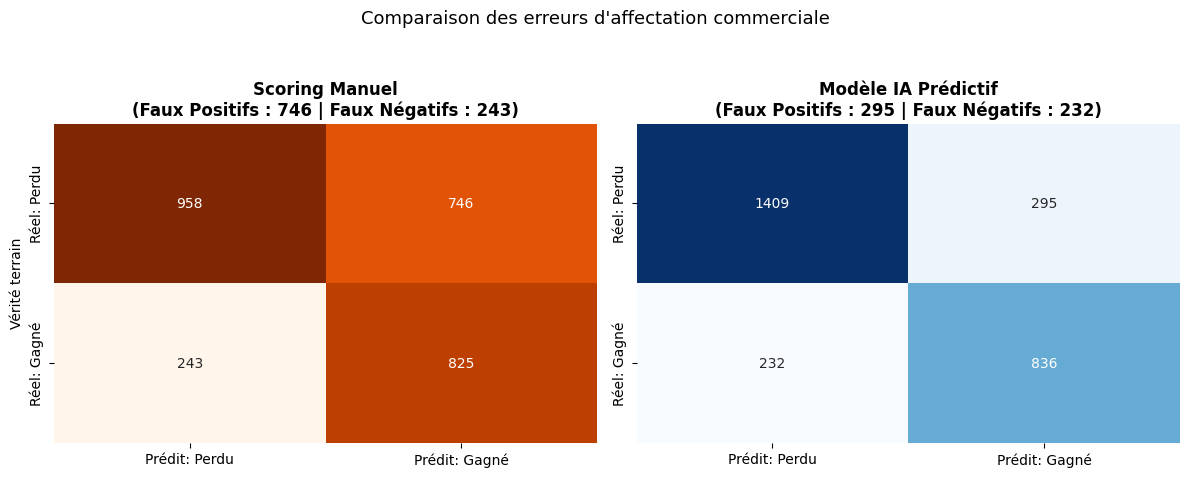

In [29]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# 1. Matrice de Confusion - Scoring Manuel
cm_man = confusion_matrix(y_test, y_pred_man_50)
sns.heatmap(cm_man, annot=True, fmt='d', cmap='Oranges', cbar=False, ax=axes[0],
            xticklabels=['Prédit: Perdu', 'Prédit: Gagné'],
            yticklabels=['Réel: Perdu', 'Réel: Gagné'])
axes[0].set_title(f"Scoring Manuel\n(Faux Positifs : {cm_man[0,1]} | Faux Négatifs : {cm_man[1,0]})", fontweight='bold')
axes[0].set_ylabel("Vérité terrain")

# 2. Matrice de Confusion - Modèle IA
cm_ia = confusion_matrix(y_test, y_pred_ia_50)
sns.heatmap(cm_ia, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[1],
            xticklabels=['Prédit: Perdu', 'Prédit: Gagné'],
            yticklabels=['Réel: Perdu', 'Réel: Gagné'])
axes[1].set_title(f"Modèle IA Prédictif\n(Faux Positifs : {cm_ia[0,1]} | Faux Négatifs : {cm_ia[1,0]})", fontweight='bold')

plt.suptitle("Comparaison des erreurs d'affectation commerciale", fontsize=13, y=1.05)
plt.tight_layout()
plt.show()

### 4.4 Analyse du Gain Cumulé (Cumulative Gains Curve)
Dans un contexte de prospection commerciale, les forces de vente disposent de ressources limitées.  
**Question marketing clé :** *« Si mes commerciaux n'ont le temps d'appeler que les 30% des meilleurs leads triés par chaque méthode, quelle proportion des clients réels vont-ils capter ? »*

/mnt/c/Users/ilyas/Desktop/Drive/lead_scoring_crm/.venv/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/mnt/c/Users/ilyas/Desktop/Drive/lead_scoring_crm/.venv/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128221 (\N{MEMO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


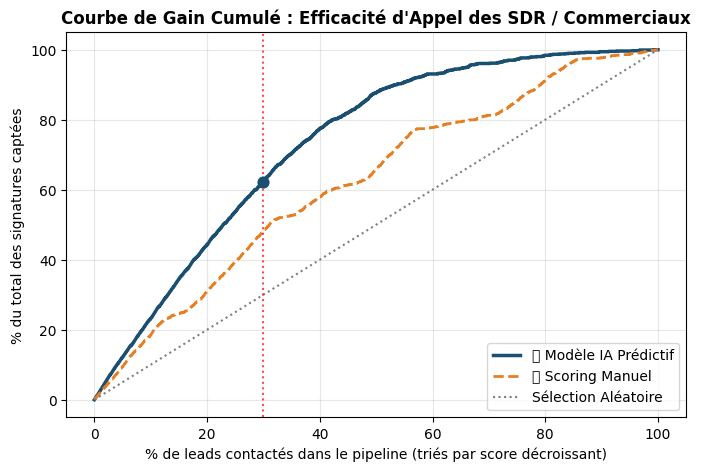

💡 En appelant seulement les 30% des meilleurs leads identifiés par l'IA,
   l'équipe commerciale sécurise 62.1% de la totalité des conversions !


In [30]:
import numpy as np

def calculate_cumulative_gains(y_true, y_scores):
    # Tri décroissant selon le score
    sorted_indices = np.argsort(y_scores)[::-1]
    y_true_sorted = np.array(y_true)[sorted_indices]
    
    # Calcul des pourcentages cumulés
    cum_conversions = np.cumsum(y_true_sorted)
    total_conversions = np.sum(y_true_sorted)
    gain = cum_conversions / total_conversions
    
    percentages = np.linspace(0, 1, len(y_true) + 1)
    gain = np.insert(gain, 0, 0)
    return percentages * 100, gain * 100

pcts, gain_ia = calculate_cumulative_gains(y_test, y_scores_ia)
_, gain_man = calculate_cumulative_gains(y_test, y_scores_manual)

plt.figure(figsize=(8, 5))
plt.plot(pcts, gain_ia, label="🎯 Modèle IA Prédictif", color="#1b4f72", lw=2.5)
plt.plot(pcts, gain_man, label="📝 Scoring Manuel", color="#e67e22", lw=2, linestyle="--")
plt.plot([0, 100], [0, 100], color="grey", linestyle=":", label="Sélection Aléatoire")

# Repère à 30% d'effort commercial
idx_30 = int(len(pcts) * 0.3)
plt.axvline(x=30, color="red", linestyle=":", alpha=0.7)
plt.scatter([30], [gain_ia[idx_30]], color="#1b4f72", s=60, zorder=5)

plt.title("Courbe de Gain Cumulé : Efficacité d'Appel des SDR / Commerciaux", fontsize=12, fontweight="bold")
plt.xlabel("% de leads contactés dans le pipeline (triés par score décroissant)")
plt.ylabel("% du total des signatures captées")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.show()

print(f"💡 En appelant seulement les 30% des meilleurs leads identifiés par l'IA,")
print(f"   l'équipe commerciale sécurise {gain_ia[idx_30]:.1f}% de la totalité des conversions !")

---
### Partie 5 : HubSpot Benchmark

In [31]:
import pandas as pd
import numpy as np

# 1. Récupération des données test scorées par l'IA et le manuel
hubspot_df = pd.DataFrame({
    # Identifiant unique obligatoire pour HubSpot
    'Email': [f"prospect_{idx}@entreprise{idx}.ma" for idx in X_test.index],
    'First Name': [f"Lead_{idx}" for idx in X_test.index],
    'Company Name': [f"Société_{idx} SARL" for idx in X_test.index],
    
    # Données Web Marketing
    'Lead Source': X_test['Lead Source'].values if 'Lead Source' in X_test.columns else 'Web Inbound',
    
    # Livrables du modèle : Scores IA et Manuel
    'Lead Score IA': np.round(y_scores_ia * 100, 1),       # Probabilité continue (ex: 88.5)
    'Lead Score Manuel': np.round(y_scores_manual * 100, 1), # Score heuristique (ex: 60.0)
    
    # Statut d'acquisition
    'Lifecycle Stage': 'Marketing Qualified Lead'
})

# 2. Exportation du fichier propre
hubspot_df.to_csv("import_hubspot_leads.csv", index=False, encoding="utf-8")
print(f"✅ Fichier prêt pour HubSpot exporté : {hubspot_df.shape[0]} contacts générés.")
display(hubspot_df.head(3))

✅ Fichier prêt pour HubSpot exporté : 2772 contacts générés.


,Email,First Name,Company Name,Lead Source,Lead Score IA,Lead Score Manuel,Lifecycle Stage
8305,prospect_8305@entreprise8305.ma,Lead_8305,Société_8305 SARL,Olark Chat,15.3,25.0,Marketing Qualified Lead
1591,prospect_1591@entreprise1591.ma,Lead_1591,Société_1591 SARL,Google,78.6,85.0,Marketing Qualified Lead
8604,prospect_8604@entreprise8604.ma,Lead_8604,Société_8604 SARL,Google,69.0,80.0,Marketing Qualified Lead
